In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Customer Purchase behavior Analysis")
print("Libraries immported successfully")

Customer Purchase behavior Analysis
Libraries immported successfully


In [2]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
# Check missing values in each column
print("Missing values:")
display(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Check column data types
print("\nColumn data types:")
print(df.dtypes)

Missing values:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Number of duplicate rows:
5268

Column data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [5]:
# Create a working copy of the original dataset
df_clean = df.copy()

# Step 1: Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Step 2: Remove rows with missing product descriptions
df_clean = df_clean.dropna(subset=["Description"])

# Step 3: Remove rows with invalid quantities or prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Step 4: Convert invoice date to datetime
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"]
)

# Step 5: Calculate transaction revenue
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original dataset rows:", len(df))
print("Cleaned dataset rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

display(df_clean.head())

Original dataset rows: 541909
Cleaned dataset rows: 524878
Rows removed: 17031


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [6]:
# Save the cleaned dataset as a CSV file
df_clean.to_csv(
    "Customer_Purchase_Cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


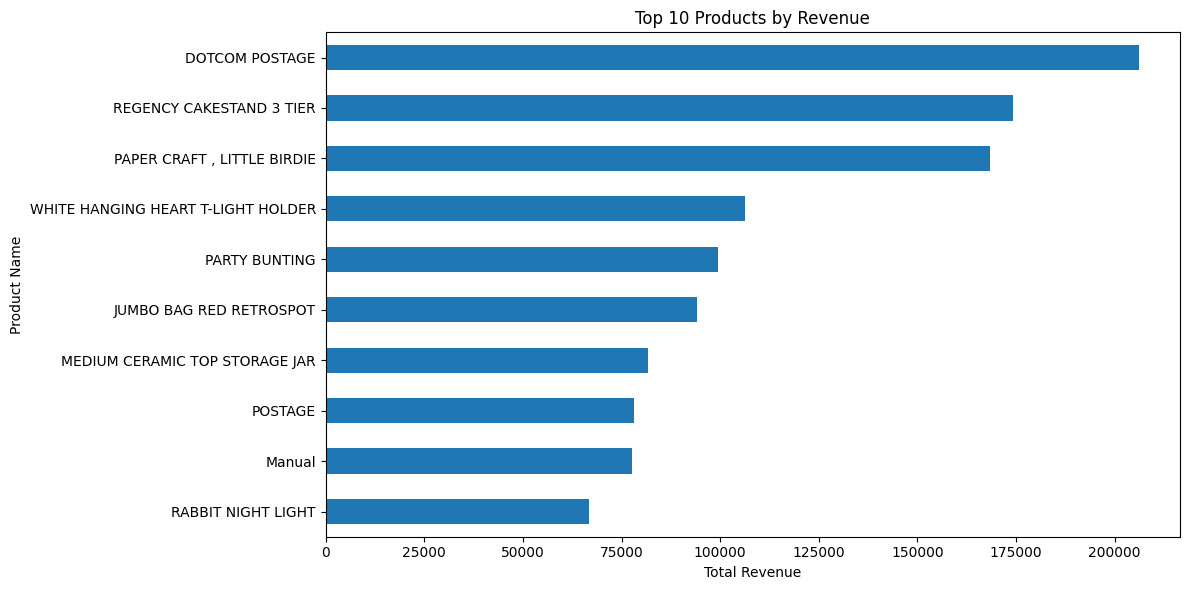

In [7]:

import matplotlib.pyplot as plt

# Find the top 10 products by revenue
top_products = (
    df_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Plot the results
plt.figure(figsize=(12, 6))
top_products.plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()


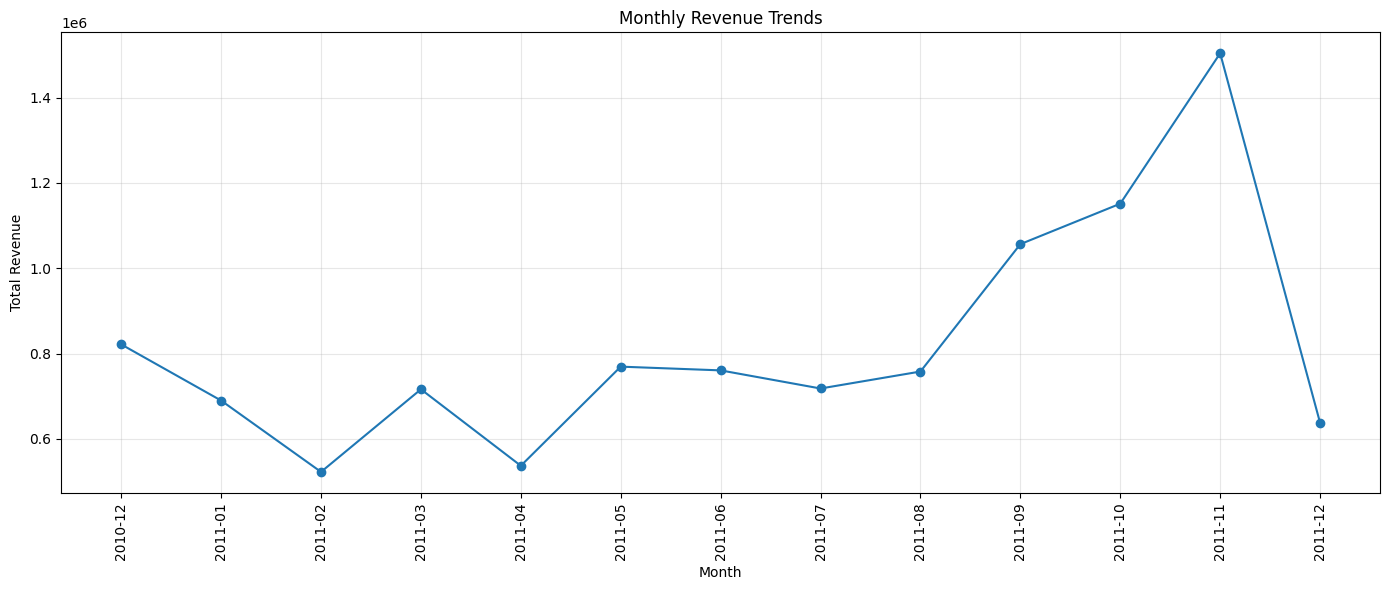

In [8]:

import matplotlib.pyplot as plt
import pandas as pd

# Extract the month from the invoice date
df_clean["YearMonth"] = (
    df_clean["InvoiceDate"].dt.to_period("M")
)

# Calculate revenue for each month
monthly_revenue = (
    df_clean.groupby("YearMonth")["Revenue"]
    .sum()
)

# Create the line chart
plt.figure(figsize=(14, 6))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trends")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


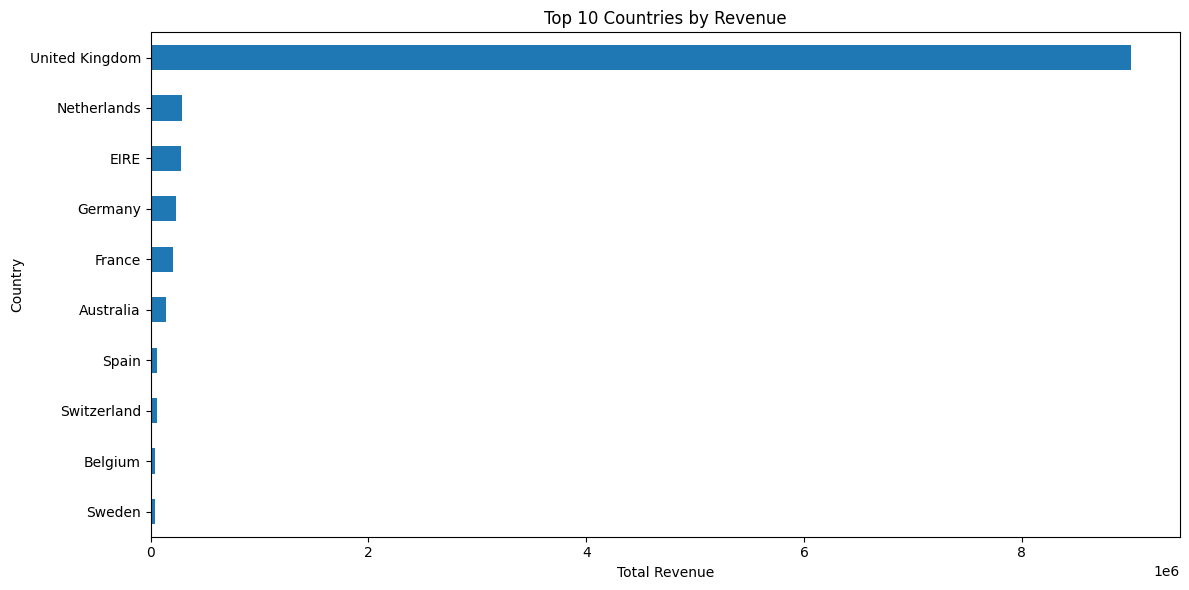

In [9]:

import matplotlib.pyplot as plt

# Calculate revenue by country
country_revenue = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 6))
country_revenue.plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


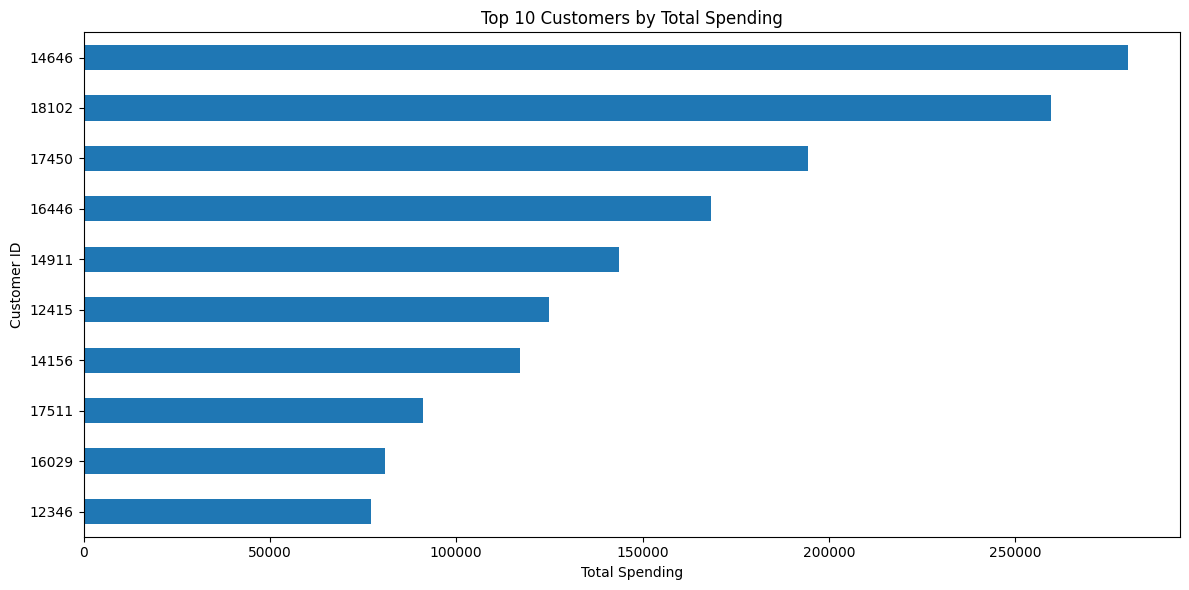

In [10]:

import matplotlib.pyplot as plt

# Remove records without a customer ID
customer_data = df_clean.dropna(subset=["CustomerID"]).copy()

# Calculate total spending per customer
top_customers = (
    customer_data.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Plot the results
plt.figure(figsize=(12, 6))
top_customers.index = top_customers.index.astype(int).astype(str)
top_customers.plot(kind="barh")

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


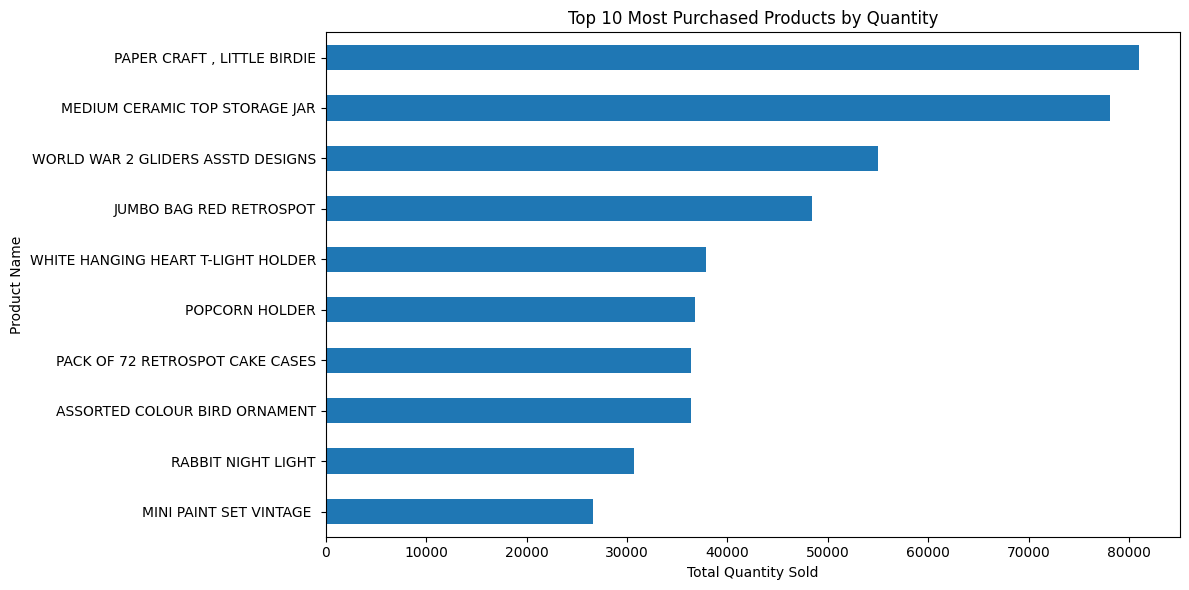

In [11]:

import matplotlib.pyplot as plt

# Calculate total quantity sold for each product
top_quantity = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Plot the top 10 products
plt.figure(figsize=(12, 6))
top_quantity.plot(kind="barh")

plt.title("Top 10 Most Purchased Products by Quantity")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()


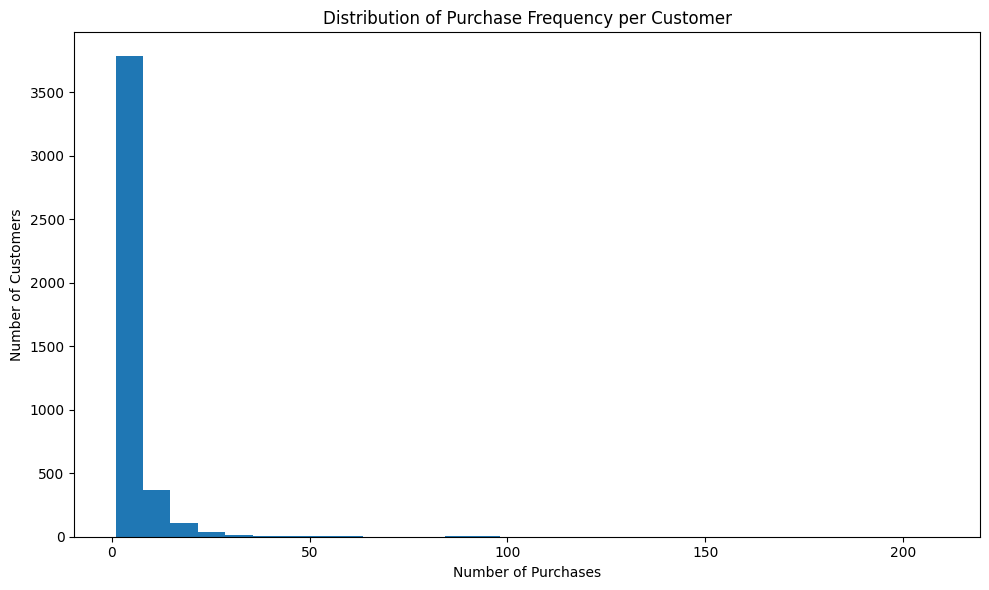

In [12]:

import matplotlib.pyplot as plt

customer_data = df_clean.dropna(subset=["CustomerID"]).copy()

purchases = customer_data.groupby("CustomerID")["InvoiceNo"].nunique()

plt.figure(figsize=(10, 6))
plt.hist(purchases, bins=30)
plt.title("Distribution of Purchase Frequency per Customer")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


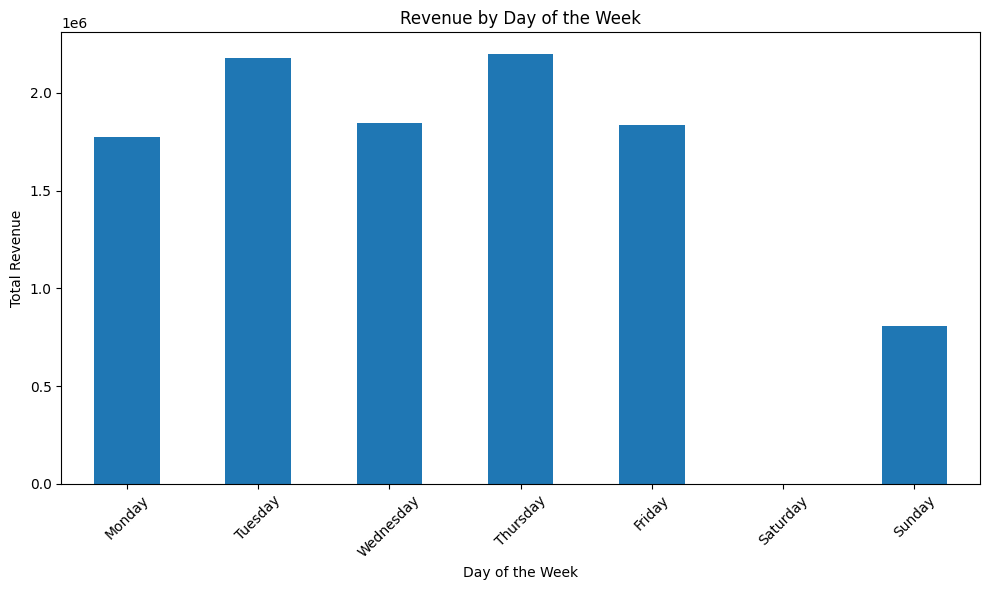

In [13]:

import matplotlib.pyplot as plt

df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_revenue = (
    df_clean.groupby("DayOfWeek")["Revenue"]
    .sum()
    .reindex(day_order)
)

plt.figure(figsize=(10, 6))
daily_revenue.plot(kind="bar")
plt.title("Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


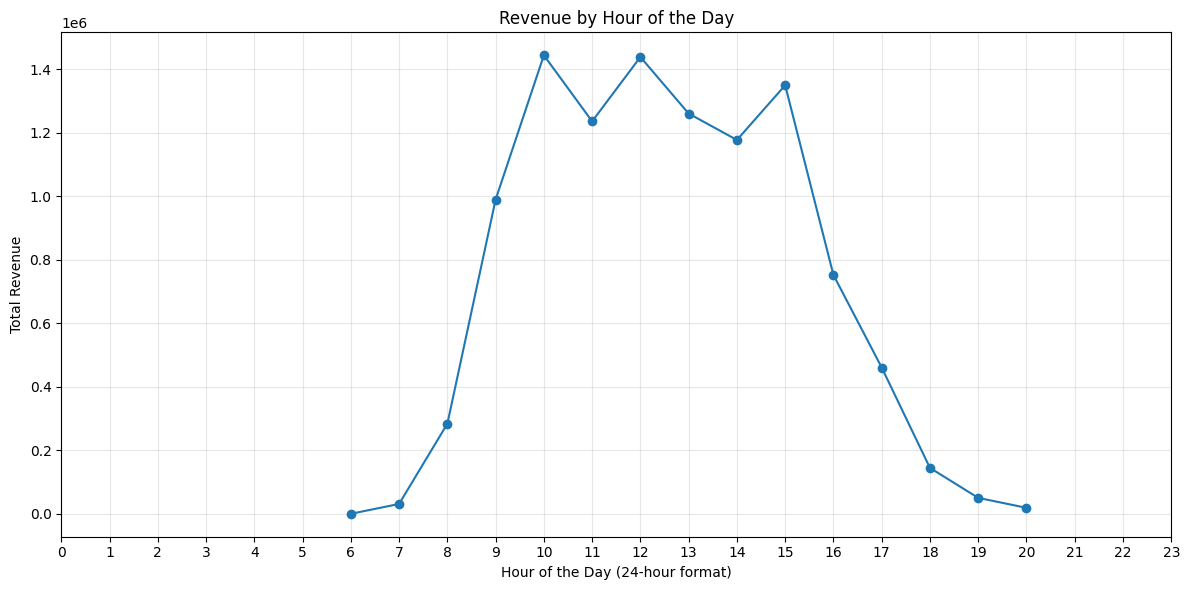

In [14]:

import matplotlib.pyplot as plt

df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

hourly_revenue = df_clean.groupby("Hour")["Revenue"].sum()

plt.figure(figsize=(12, 6))
hourly_revenue.plot(kind="line", marker="o")
plt.title("Revenue by Hour of the Day")
plt.xlabel("Hour of the Day (24-hour format)")
plt.ylabel("Total Revenue")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


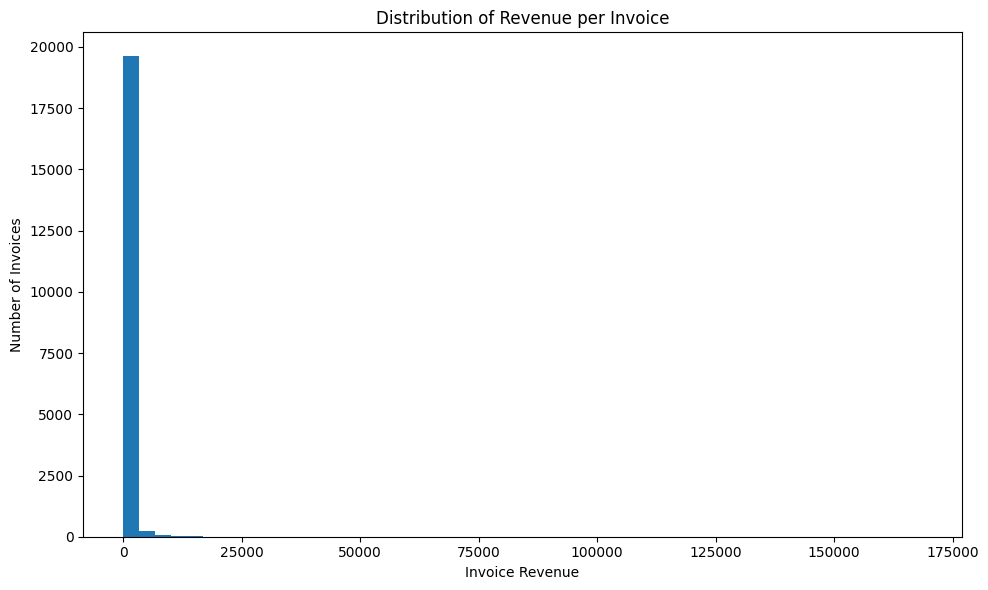

In [15]:

import matplotlib.pyplot as plt

invoice_revenue = df_clean.groupby("InvoiceNo")["Revenue"].sum()

plt.figure(figsize=(10, 6))
plt.hist(invoice_revenue, bins=50)
plt.title("Distribution of Revenue per Invoice")
plt.xlabel("Invoice Revenue")
plt.ylabel("Number of Invoices")
plt.tight_layout()
plt.show()


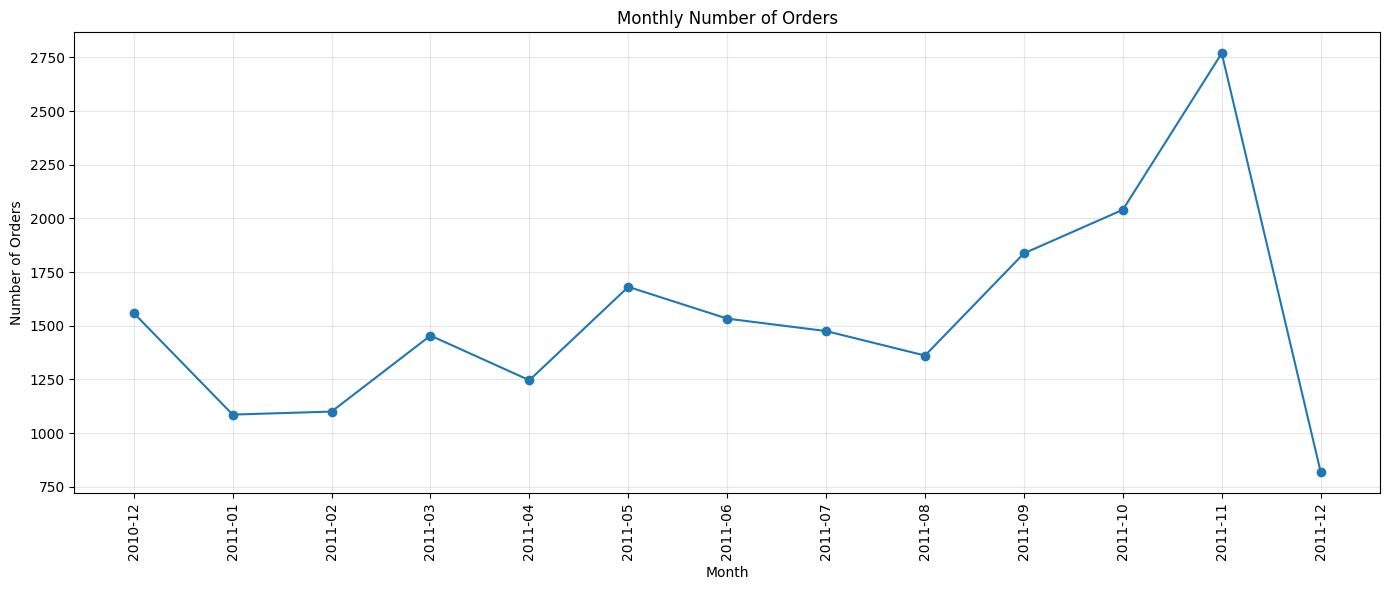

In [16]:

import matplotlib.pyplot as plt

df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M")

monthly_orders = df_clean.groupby("YearMonth")["InvoiceNo"].nunique()

plt.figure(figsize=(14, 6))
plt.plot(
    monthly_orders.index.astype(str),
    monthly_orders.values,
    marker="o"
)
plt.title("Monthly Number of Orders")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [17]:

print("Total cleaned transactions:", len(df_clean))
print("Total revenue:", round(df_clean["Revenue"].sum(), 2))
print("Unique invoices:", df_clean["InvoiceNo"].nunique())
print("Unique products:", df_clean["Description"].nunique())
print("Unique countries:", df_clean["Country"].nunique())
print("Unique customers:", df_clean["CustomerID"].nunique())


Total cleaned transactions: 524878
Total revenue: 10642110.8
Unique invoices: 19960
Unique products: 4026
Unique countries: 38
Unique customers: 4338


### Dataset Summary

- Cleaned records: 524,878
- Total revenue: £10,642,110.80
- Unique invoices: 19,960
- Unique products: 4,070
- Unique countries: 38
- Unique customers: 4,338

### Five Observations from Exploratory Data Analysis

1. **Data cleaning:** The original dataset contained 541,909 rows. After cleaning, 524,878 rows remained.
2. **Revenue:** Total revenue in the cleaned dataset was £10,642,110.80.
3. **Orders:** The dataset contains 19,960 unique invoices.
4. **Product variety:** The dataset contains 4,070 distinct product descriptions.
5. **International sales:** The dataset includes transactions from 38 countries.

### Three Business Insights

1. **Product assortment:** Analysing product revenue and quantities can help identify popular products and improve inventory planning.
2. **Customer retention:** Purchase frequency and spending analysis can help identify repeat customers and support loyalty programmes.
3. **Market opportunities:** Comparing revenue across countries can help identify strong markets and areas where sales could be improved.